# 6. Method comparison

Scores every method that has saved predictions, so run 03 to 05 first. Methods that have not been run are left out of the tables.

**Reads:** `intermediate/sentences.pkl`, `intermediate/gold_sentences.csv`, `predictions/`, `intermediate/m1_hits.csv`.
**Writes:** M4 predictions, `method_comparison.csv` (dev and test rows), `method_comparison.png`, and an error review sheet for the best method.

The best method is chosen on **dev**. The **test** row is the score to report: no method learned from or was tuned on those judgments. The error review uses dev sentences only, so the test judgments stay unseen.

## Setup

In [1]:
from argmine_common import *
import matplotlib.pyplot as plt

sents = load_sentences()
GOLD_IDX, Y, DOCS, gold_docs, TEST = load_gold()
TITLE = titles(load_corpus())

## M4: hybrid (M1 or M2)

Keywords and citations give precise anchors; exemplar similarity adds recall on paraphrased reasoning. A sentence gets a category if either method assigns it.

In [2]:
preds = load_preds()
m1, m2 = preds.get("M1 revised keywords"), preds.get("M2 exemplar similarity")
if m1 and m2:
    save_preds("M4 hybrid M1 + M2", np.maximum(m1["gold"], m2["gold"]), np.maximum(m1["all"], m2["all"]))
    preds = load_preds()
else:
    print("Skipping M4: it needs M1 (03_keyword_methods) and M2 (04_exemplar_similarity).")

PRED = {name: p["gold"] for name, p in preds.items()}
print("Methods loaded:", ", ".join(PRED))

Methods loaded: M0 original keywords, M1 revised keywords, M1n + negation filter, M1p + skip party arguments, M2 exemplar similarity, M4 hybrid M1 + M2, M6 fine-tuned, keywords then highlights, M6g fine-tuned on lawyer highlights, M6s fine-tuned on keyword labels


## How methods are scored

* **Sentence level:** precision, recall and F1 per category, micro and macro averages. Macro F1 averages only over categories present in the gold data.
* **Judgment level:** a judgment "contains" a category if any of its sentences does. This is the level the outcome analysis uses.
* **Uncertainty:** 95% intervals from resampling whole judgments (1,000 draws). With about 15 judgments these intervals will be wide, and we report them rather than hide them.
* **Comparisons:** paired bootstrap over judgments, giving the share of resamples in which method A beats method B on macro F1.

The helpers are in `argmine_common.py`.

## Results

In [3]:
rows = []
for split, mask in (("dev", ~TEST), ("test", TEST)):
    Yt, Dt = Y[mask], DOCS[mask]
    for name, P in PRED.items():
        Pt = P[mask]
        s = summarize(Yt, Pt)
        lo, hi = boot_ci(Yt, Pt, Dt)
        c = summarize(to_case_level(Yt, Dt), to_case_level(Pt, Dt))
        rows.append({"split": split, "method": name, **{k: round(v, 3) for k, v in s.items()},
                     "ci_low": round(lo, 3), "ci_high": round(hi, 3),
                     "case_macro_F1": round(c["macro_F1"], 3), "case_micro_F1": round(c["micro_F1"], 3)})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "method_comparison.csv", index=False)

DEV_RES = results[results.split == "dev"].set_index("method")
TEST_RES = results[results.split == "test"].set_index("method")
BEST = DEV_RES.macro_F1.idxmax()
print(f"Dev: {len(set(DOCS[~TEST]))} judgments, {(~TEST).sum()} sentences. "
      f"Test: {len(set(DOCS[TEST]))} judgments, {TEST.sum()} sentences.")
print(f"Best method on dev: {BEST}\n")
display(DEV_RES.drop(columns="split").style.set_caption("Dev (used to choose and revise methods)"))
TEST_RES.drop(columns="split").style.set_caption("Test (report these)")

Dev: 12 judgments, 424 sentences. Test: 3 judgments, 65 sentences.
Best method on dev: M1 revised keywords



,macro_P,macro_R,macro_F1,micro_F1,exact_match_acc,ci_low,ci_high,case_macro_F1,case_micro_F1
method,,,,,,,,,
M0 original keywords,0.312000,0.128000,0.143000,0.222000,0.715000,0.030000,0.273000,0.441000,0.533000
M1 revised keywords,0.282000,0.310000,0.291000,0.333000,0.717000,0.158000,0.396000,0.650000,0.679000
M1n + negation filter,0.295000,0.281000,0.279000,0.318000,0.733000,0.153000,0.380000,0.663000,0.692000
M1p + skip party arguments,0.282000,0.310000,0.291000,0.333000,0.717000,0.158000,0.396000,0.650000,0.679000
M2 exemplar similarity,0.050000,0.387000,0.080000,0.082000,0.205000,0.059000,0.119000,0.510000,0.519000
M4 hybrid M1 + M2,0.086000,0.583000,0.139000,0.133000,0.198000,0.094000,0.196000,0.534000,0.550000
"M6 fine-tuned, keywords then highlights",0.123000,0.153000,0.136000,0.195000,0.646000,0.063000,0.217000,0.483000,0.533000
M6g fine-tuned on lawyer highlights,0.042000,0.099000,0.057000,0.100000,0.517000,0.019000,0.137000,0.384000,0.491000
M6s fine-tuned on keyword labels,0.229000,0.189000,0.201000,0.263000,0.698000,0.105000,0.307000,0.574000,0.588000


,macro_P,macro_R,macro_F1,micro_F1,exact_match_acc,ci_low,ci_high,case_macro_F1,case_micro_F1
method,,,,,,,,,
M0 original keywords,0.300000,0.133000,0.175000,0.174000,0.723000,0.000000,0.500000,0.417000,0.615000
M1 revised keywords,0.222000,0.267000,0.238000,0.276000,0.723000,0.195000,0.500000,0.617000,0.800000
M1n + negation filter,0.321000,0.267000,0.283000,0.308000,0.738000,0.222000,0.500000,0.667000,0.857000
M1p + skip party arguments,0.222000,0.267000,0.238000,0.276000,0.723000,0.195000,0.500000,0.617000,0.800000
M2 exemplar similarity,0.096000,0.483000,0.150000,0.117000,0.308000,0.042000,0.533000,0.700000,0.636000
M4 hybrid M1 + M2,0.112000,0.567000,0.178000,0.128000,0.292000,0.145000,0.533000,0.700000,0.636000
"M6 fine-tuned, keywords then highlights",0.172000,0.233000,0.171000,0.258000,0.677000,0.000000,0.750000,0.375000,0.615000
M6g fine-tuned on lawyer highlights,0.108000,0.183000,0.134000,0.182000,0.631000,0.000000,0.583000,0.833000,0.875000
M6s fine-tuned on keyword labels,0.146000,0.183000,0.160000,0.214000,0.708000,0.000000,0.500000,0.617000,0.800000


In [4]:
# Per category F1 for every method, on dev
f1_table = pd.DataFrame({name: per_category(Y[~TEST], P[~TEST]).f1 for name, P in PRED.items()}).T
f1_table.loc[:, Y[~TEST].sum(0) == 0] = np.nan      # no gold examples: F1 is undefined, not zero
f1_table.round(2)

,Ingredients/exceptions,Speech vs reputation,Procedural,Insufficient evidence,Abuse of process
M0 original keywords,0.41,0.00,0.14,0.00,0.17
M1 revised keywords,0.45,0.17,0.33,0.24,0.26
M1n + negation filter,0.41,0.17,0.34,0.20,0.28
M1p + skip party arguments,0.45,0.17,0.33,0.24,0.26
M2 exemplar similarity,0.10,0.06,0.10,0.07,0.07
M4 hybrid M1 + M2,0.27,0.08,0.12,0.08,0.15
"M6 fine-tuned, keywords then highlights",0.36,0.00,0.13,0.00,0.18
M6g fine-tuned on lawyer highlights,0.19,0.00,0.00,0.00,0.10
M6s fine-tuned on keyword labels,0.47,0.00,0.16,0.08,0.29


In [5]:
# Paired bootstrap on test: is each method better than the original keywords (M0) and the revised keywords (M1)?
# With only a few test judgments these intervals are wide.
cmp_rows = []
for base in ["M0 original keywords", "M1 revised keywords"]:
    for name, P in PRED.items():
        if name == base or base not in PRED:
            continue
        d, (lo, hi), p_better = paired_boot(Y[TEST], P[TEST], PRED[base][TEST], DOCS[TEST])
        cmp_rows.append({"method": name, "vs": base, "delta_macro_F1": round(d, 3),
                         "95% CI": f"[{lo:+.2f}, {hi:+.2f}]", "P(better)": round(p_better, 2)})
pd.DataFrame(cmp_rows)

,method,vs,delta_macro_F1,95% CI,P(better)
0,M1 revised keywords,M0 original keywords,0.060,"[-0.13, +0.22]",0.74
1,M1n + negation filter,M0 original keywords,0.118,"[+0.00, +0.22]",0.96
2,M1p + skip party arguments,M0 original keywords,0.060,"[-0.13, +0.22]",0.74
3,M2 exemplar similarity,M0 original keywords,-0.014,"[-0.16, +0.16]",0.55
4,M4 hybrid M1 + M2,M0 original keywords,0.016,"[-0.19, +0.18]",0.77
5,"M6 fine-tuned, keywords then highlights",M0 original keywords,0.010,"[-0.12, +0.25]",0.51
6,M6g fine-tuned on lawyer highlights,M0 original keywords,-0.026,"[-0.10, +0.08]",0.14
7,M6s fine-tuned on keyword labels,M0 original keywords,-0.017,"[-0.11, +0.08]",0.25
8,M0 original keywords,M1 revised keywords,-0.060,"[-0.22, +0.13]",0.23
9,M1n + negation filter,M1 revised keywords,0.058,"[+0.00, +0.20]",0.71


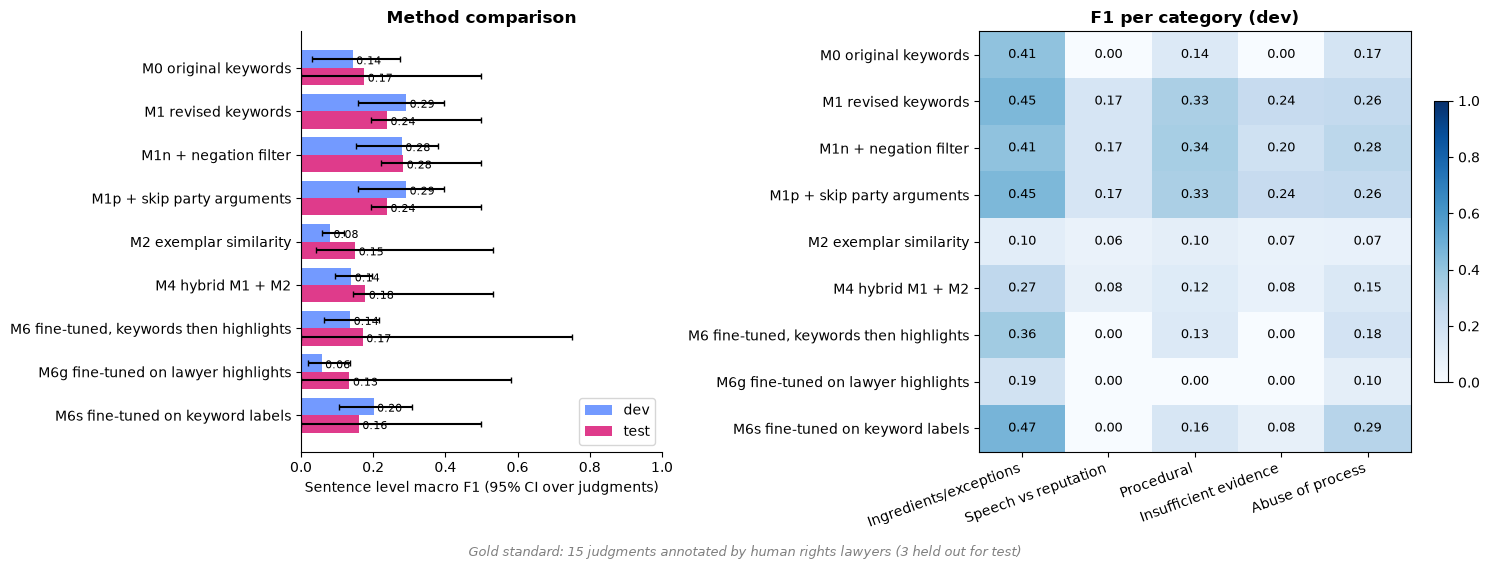

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
names = list(PRED)
pos = np.arange(len(names))
for k, (res, label, color) in enumerate([(DEV_RES, "dev", "#648FFF"), (TEST_RES, "test", "#DC267F")]):
    r = res.loc[names]
    vals = r.macro_F1.values
    ax.barh(pos + (k - 0.5) * 0.4, vals, height=0.4, color=color, alpha=0.9,
            xerr=[vals - r.ci_low.values, r.ci_high.values - vals], capsize=2, label=label)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, pos[i] + (k - 0.5) * 0.4 + 0.12, f"{v:.2f}", fontsize=8)
ax.set_yticks(pos)
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Sentence level macro F1 (95% CI over judgments)")
ax.set_title("Method comparison", fontweight="bold")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
im = ax.imshow(np.ma.masked_invalid(f1_table.values.astype(float)), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(K))
ax.set_xticklabels(f1_table.columns, rotation=20, ha="right")
ax.set_yticks(range(len(f1_table)))
ax.set_yticklabels(f1_table.index)
for i in range(f1_table.shape[0]):
    for j in range(K):
        v = f1_table.values[i, j]
        ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if (not np.isnan(v) and v > 0.6) else "black")
ax.set_title("F1 per category (dev)", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.text(0.5, -0.02, f"Gold standard: {len(gold_docs)} judgments annotated by human rights lawyers "
         f"({len(set(DOCS[TEST]))} held out for test)", ha="center", fontsize=9, color="gray", style="italic")
plt.tight_layout()
plt.savefig(OUT_DIR / "method_comparison.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Error review

In [7]:
# ── Error review sheet for the best method, dev sentences only ────────────────
hits = (pd.read_csv(M1_HITS_CSV) if M1_HITS_CSV.exists()
        else pd.DataFrame(columns=["sid", "cat", "match", "source", "negated"]))
MATCHED = (hits.match + np.where(hits.negated.astype(bool), " (negated)", "")).groupby([hits.sid, hits.cat]).agg("; ".join)
P = PRED[BEST]
err = []
for j, c in enumerate(CATS):
    for kind, mask in (("false positive", (P[:, j] == 1) & (Y[:, j] == 0)),
                       ("false negative", (P[:, j] == 0) & (Y[:, j] == 1))):
        for r in np.where(mask & ~TEST)[0]:
            sid = GOLD_IDX[r]
            err.append({"category": SHORT[c], "error": kind, "judgment": TITLE.get(DOCS[r], DOCS[r]),
                        "para_no": sents.para_no[sid], "in_quote": sents.in_quote[sid],
                        "party_argument": sents.party_argument[sid],
                        "matched": MATCHED.get((sid, c), ""),
                        "text": sents.text[sid]})
err = pd.DataFrame(err)
err.to_csv(OUT_DIR / f"errors_{re.sub(r'[^A-Za-z0-9]+', '_', BEST)}.csv", index=False)
print(f"Best method: {BEST}. {len(err)} errors written for review.")
err.groupby(["category", "error"]).size().unstack(fill_value=0)

Best method: M1 revised keywords. 140 errors written for review.


error,false negative,false positive
category,,
Abuse of process,16,13
Ingredients/exceptions,20,16
Insufficient evidence,12,13
Procedural,13,27
Speech vs reputation,4,6


## Notes for the paper

* Report the M0 to M1 to M2 to M4 table with confidence intervals; with about 15 judgments the intervals are wide, and reviewers will expect them.
* The M1 versus M1n comparison decides the negation wording in Methods: if M1 scores higher, negated mentions should be described as "recorded for direction" rather than "discarded".
* Report M6 with its ablations: M6s (keyword labels only) and M6g (lawyer highlights only) show what each source of supervision adds.
* The F1 scores printed in `nidhi_working.ipynb` measured agreement with keyword labels, not correctness, so they should not be compared with the numbers here.